## Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

## Load Dataset

In [3]:
df=pd.read_csv("Bankruptcy_prevention_Dataset.csv",sep=";")

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

df.head()


,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,class
0,0.5,1.0,0.0,0.0,0.0,0.5,bankruptcy
1,0.0,1.0,0.0,0.0,0.0,1.0,bankruptcy
2,1.0,0.0,0.0,0.0,0.0,1.0,bankruptcy
3,0.5,0.0,0.0,0.5,0.0,1.0,bankruptcy
4,1.0,1.0,0.0,0.0,0.0,1.0,bankruptcy


In [4]:
df.columns

Index(['industrial_risk', 'management_risk', 'financial_flexibility',
       'credibility', 'competitiveness', 'operating_risk', 'class'],
      dtype='object')

In [5]:
df.shape

(250, 7)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   industrial_risk        250 non-null    float64
 1   management_risk        250 non-null    float64
 2   financial_flexibility  250 non-null    float64
 3   credibility            250 non-null    float64
 4   competitiveness        250 non-null    float64
 5   operating_risk         250 non-null    float64
 6   class                  250 non-null    object 
dtypes: float64(6), object(1)
memory usage: 13.8+ KB


In [7]:
df.isnull().sum()

industrial_risk          0
management_risk          0
financial_flexibility    0
credibility              0
competitiveness          0
operating_risk           0
class                    0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(147)

In [9]:
##Statistical summary
df.describe()

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk
count,250.000000,250.000000,250.000000,250.000000,250.000000,250.000000
mean,0.518000,0.614000,0.376000,0.470000,0.476000,0.570000
std,0.411526,0.410705,0.401583,0.415682,0.440682,0.434575
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.500000,0.000000,0.000000,0.000000,0.000000
50%,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000
75%,1.000000,1.000000,0.500000,1.000000,1.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [10]:
df["class"].value_counts()

class
non-bankruptcy    143
bankruptcy        107
Name: count, dtype: int64

In [11]:
df["class"].value_counts(normalize=True) * 100

class
non-bankruptcy    57.2
bankruptcy        42.8
Name: proportion, dtype: float64

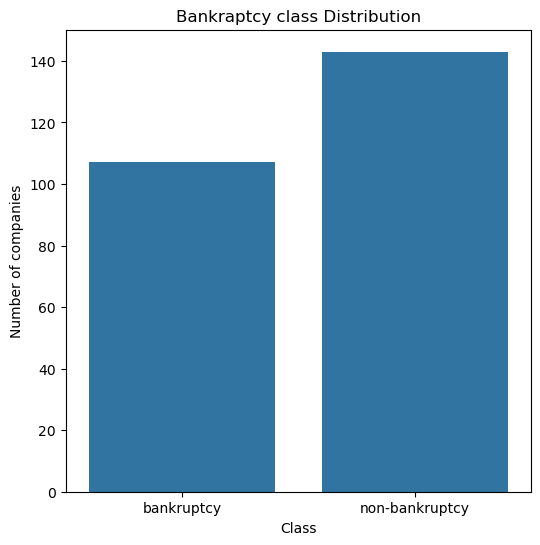

In [12]:
plt.figure(figsize=(6,6))
sns.countplot(data=df,x="class")

plt.title("Bankraptcy class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of companies")
plt.show()

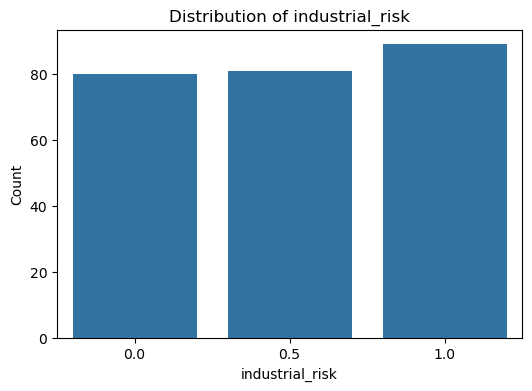

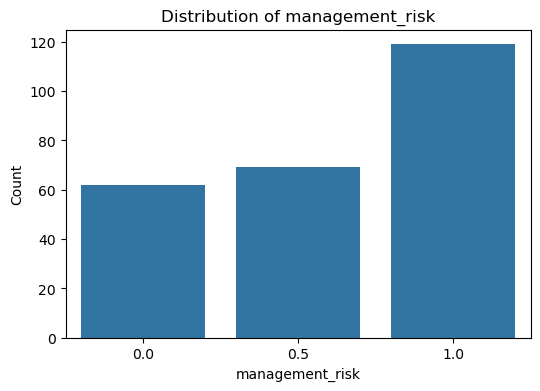

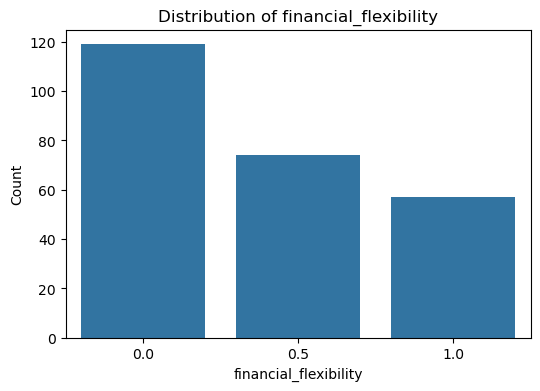

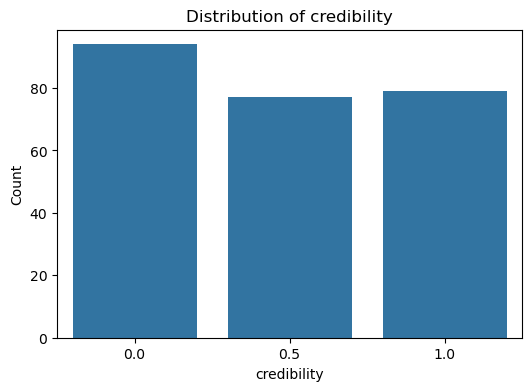

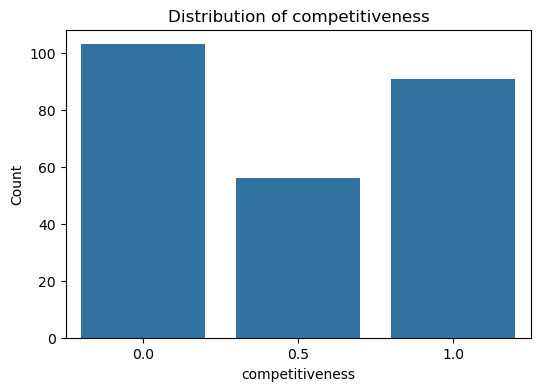

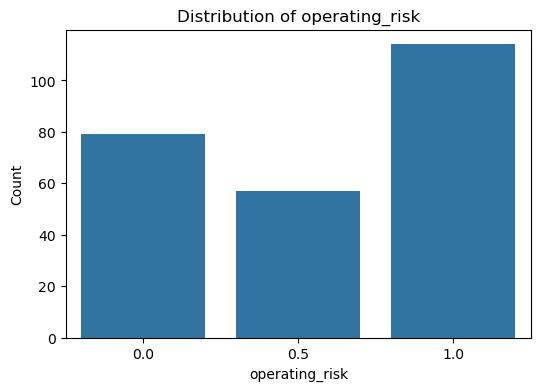

In [13]:
features = [
    "industrial_risk",
    "management_risk",
    "financial_flexibility",
    "credibility",
    "competitiveness",
    "operating_risk"
]

for column in features:
    plt.figure(figsize=(6,4))
    sns.countplot(data=df, x=column)
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Count")
    plt.show()

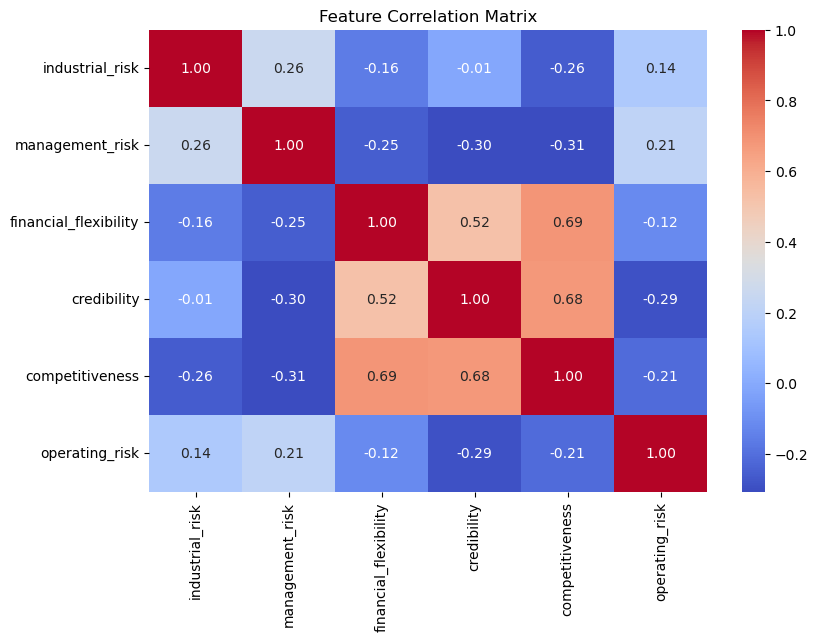

In [14]:
plt.figure(figsize=(9,6))

sns.heatmap(
    df[features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Matrix")
plt.show()

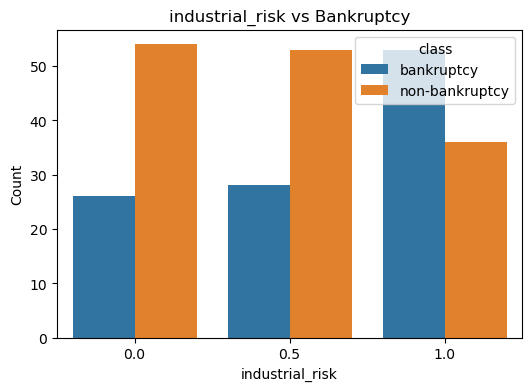

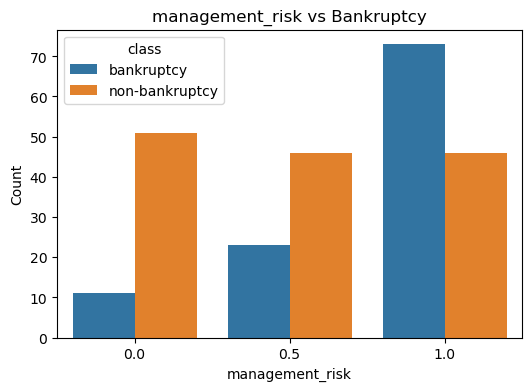

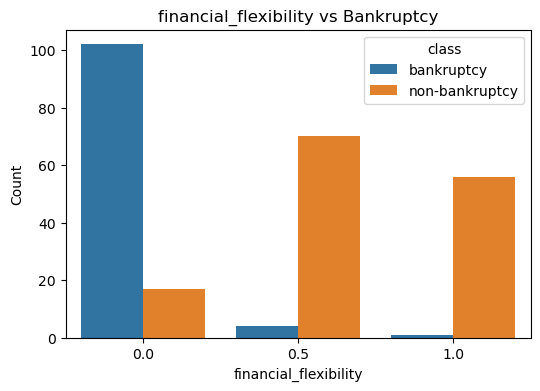

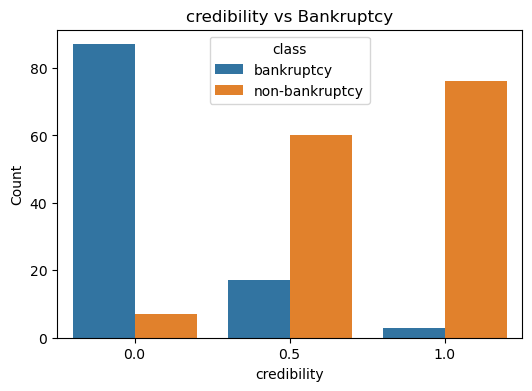

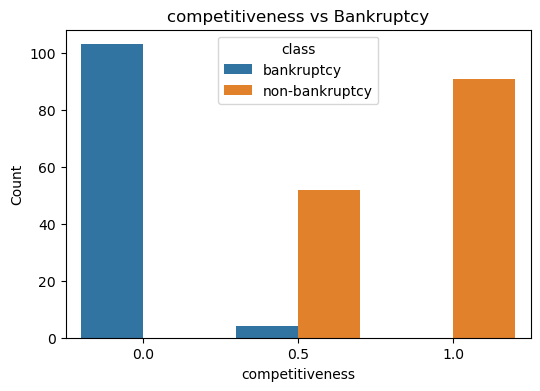

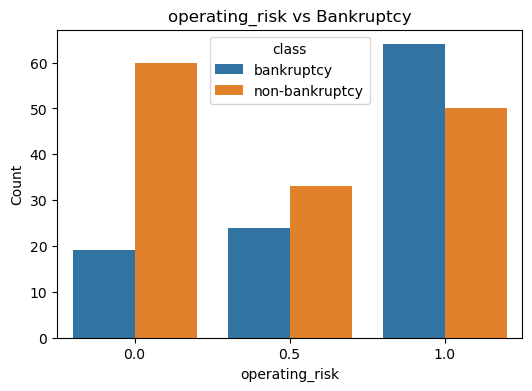

In [15]:
for column in features:
    plt.figure(figsize=(6,4))
    
    sns.countplot(
        data=df,
        x=column,
        hue="class"
    )
    
    plt.title(f"{column} vs Bankruptcy")
    plt.xlabel(column)
    plt.ylabel("Count")
    plt.show()

In [16]:
df.duplicated().sum()

np.int64(147)

In [17]:
df[df.duplicated()]

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,class
11,0.0,1.0,0.0,0.0,0.0,1.0,bankruptcy
13,1.0,1.0,0.0,0.0,0.0,1.0,bankruptcy
15,0.5,1.0,0.0,0.0,0.0,0.5,bankruptcy
16,0.5,1.0,0.0,0.0,0.0,0.5,bankruptcy
18,0.5,1.0,0.0,0.0,0.0,1.0,bankruptcy
...,...,...,...,...,...,...,...
245,0.0,1.0,1.0,1.0,1.0,1.0,non-bankruptcy
246,1.0,1.0,0.5,1.0,1.0,0.0,non-bankruptcy
247,0.0,1.0,1.0,0.5,0.5,0.0,non-bankruptcy
248,1.0,0.0,0.5,1.0,0.5,0.0,non-bankruptcy


Duplicate Treatment
---

In [18]:
df = df.drop_duplicates().reset_index(drop=True)

In [19]:
df.shape

(103, 7)

In [20]:
df.duplicated().sum()

np.int64(0)

Outlier Analysis
--

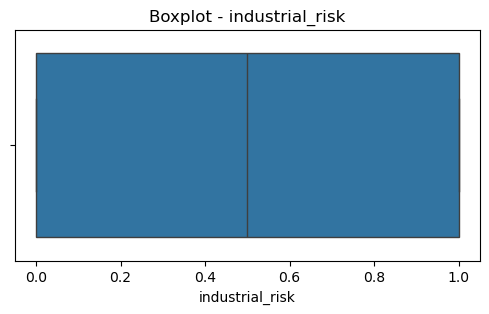

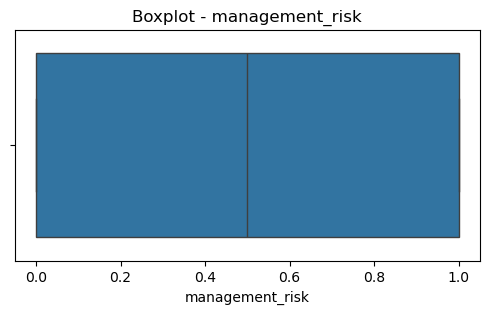

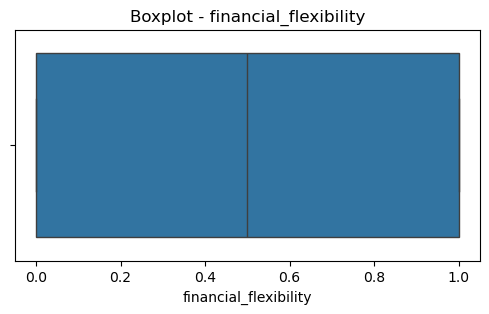

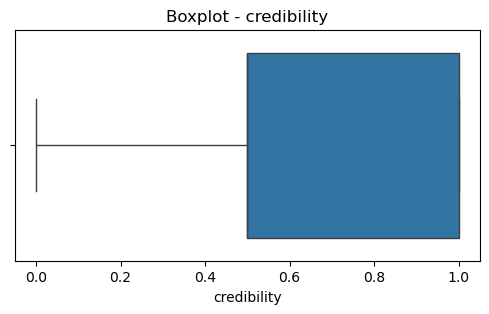

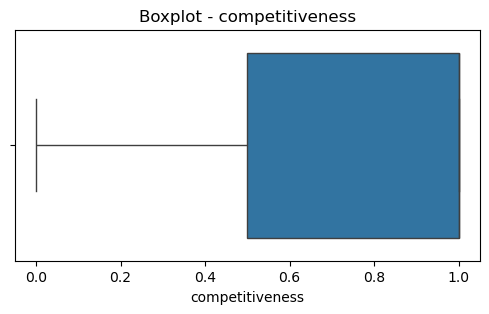

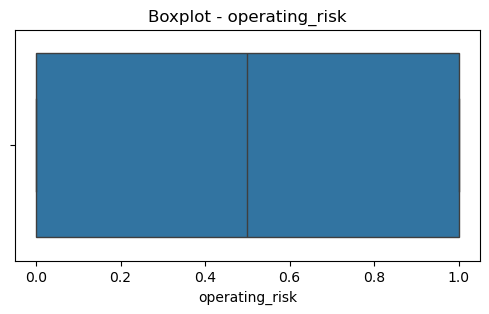

In [21]:
for col in features:

    plt.figure(figsize=(6,3))

    sns.boxplot(x=df[col])

    plt.title(f"Boxplot - {col}")

    plt.show()

In [22]:
x=df.iloc[:,:6]
y=df["class"]

In [23]:
## Encoding the target variable
y = y.map({
    'bankruptcy': 1,
    'non-bankruptcy': 0
})

In [24]:
y.value_counts()

class
0    78
1    25
Name: count, dtype: int64

In [25]:
from sklearn.model_selection import train_test_split,cross_val_score
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

Feature Scaling
--

The features are already between 0 and 1, but scaling is still useful for algorithms such as:

Logistic Regression
KNN
SVM

Instead of scaling manually, use Pipeline.

This prevents data leakage.

In [26]:
##Logistic Regression
logistic_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression())
])

In [27]:
logistic_model.fit(x_train,y_train)

,steps,"[('scaler', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0


In [28]:
y_pred_lr=logistic_model.predict(x_test)

In [29]:
##Accuracy
accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Accuracy:", round(accuracy_lr,3))

Accuracy: 0.952


In [30]:
# Logistic Regression Classification Report
print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=[
            'Non-bankruptcy',
            'Bankruptcy'
        ]
    )
)

                precision    recall  f1-score   support

Non-bankruptcy       0.94      1.00      0.97        16
    Bankruptcy       1.00      0.80      0.89         5

      accuracy                           0.95        21
     macro avg       0.97      0.90      0.93        21
  weighted avg       0.96      0.95      0.95        21



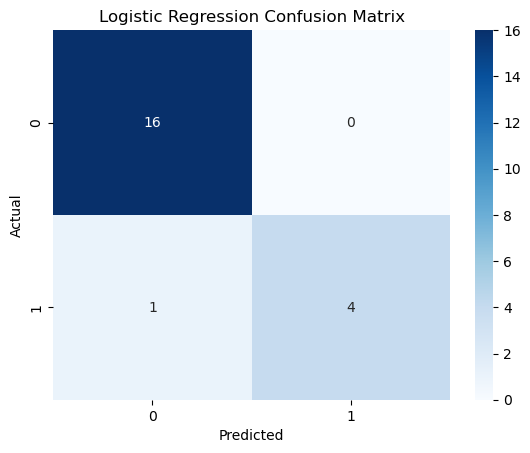

In [31]:
#Logistic Regression Confusion Matrix
cm = confusion_matrix(y_test, y_pred_lr)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")

plt.show()

In [32]:
knn_model= Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsClassifier(n_neighbors=5))
])

In [33]:
knn_model.fit(x_train,y_train)

,steps,"[('scaler', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30


In [34]:
y_pred_knn=knn_model.predict(x_test)

In [35]:
accuracy_knn=accuracy_score(y_test,y_pred_knn)
print("Knn_Accuracy",round(accuracy_knn,3))


Knn_Accuracy 0.952


In [36]:
# KNN Classification Report
print(
    classification_report(
        y_test,
        y_pred_knn,
        target_names=[
            'Non-bankruptcy',
            'Bankruptcy'
        ]
    )
)

                precision    recall  f1-score   support

Non-bankruptcy       0.94      1.00      0.97        16
    Bankruptcy       1.00      0.80      0.89         5

      accuracy                           0.95        21
     macro avg       0.97      0.90      0.93        21
  weighted avg       0.96      0.95      0.95        21



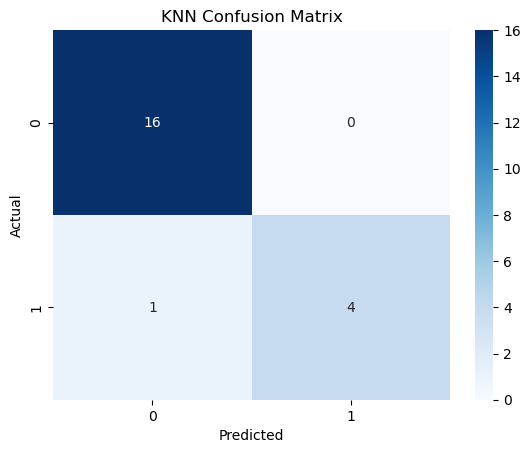

In [37]:
# KNN confusion matrix
cm = confusion_matrix(y_test, y_pred_knn)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN Confusion Matrix")

plt.show()

In [38]:
# Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier
dt_model = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

In [39]:
dt_model.fit(x_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,4
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [40]:
y_pred_dt=dt_model.predict(x_test)

In [41]:
DT_Accuracy=(accuracy_score(y_test,y_pred_dt))

In [42]:
print(f"Accuracy_Score_DT:{DT_Accuracy:.3f}")

Accuracy_Score_DT:0.952


In [43]:
#DT Classification Report
print(
    classification_report(
        y_test,
        y_pred_dt,
        target_names=[
            'Non-bankruptcy',
            'Bankruptcy'
        ]
    )
)

                precision    recall  f1-score   support

Non-bankruptcy       0.94      1.00      0.97        16
    Bankruptcy       1.00      0.80      0.89         5

      accuracy                           0.95        21
     macro avg       0.97      0.90      0.93        21
  weighted avg       0.96      0.95      0.95        21



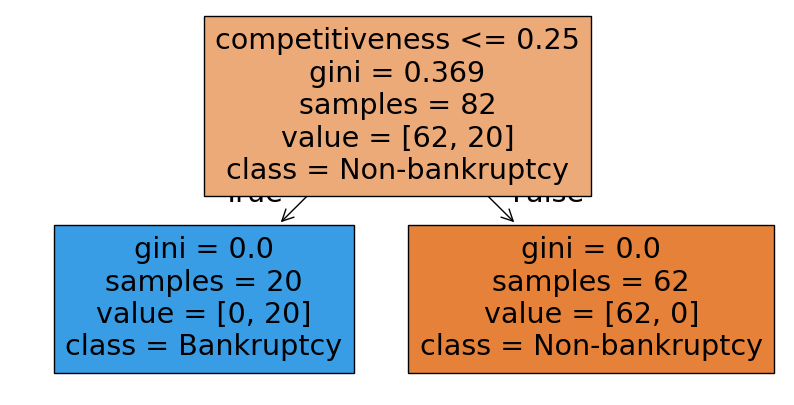

In [44]:
from sklearn.tree import plot_tree

plt.figure(figsize=(10,5))

plot_tree(
    dt_model,
    feature_names=x.columns,
    class_names=[
        'Non-bankruptcy',
        'Bankruptcy'
    ],
    filled=True
)

plt.show()

In [45]:
#Random forest classifier
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    random_state=42
)

In [46]:
rf_model.fit(x_train, y_train)

,n_estimators,200
,criterion,'gini'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [47]:
y_pred_rf = rf_model.predict(x_test)

In [48]:
accuracy_rf = accuracy_score(
    y_test,
    y_pred_rf
)

print("Random Forest Accuracy:", accuracy_rf)

Random Forest Accuracy: 0.9523809523809523


In [49]:
print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=[
            'Non-bankruptcy',
            'Bankruptcy'
        ]
    )
)

                precision    recall  f1-score   support

Non-bankruptcy       0.94      1.00      0.97        16
    Bankruptcy       1.00      0.80      0.89         5

      accuracy                           0.95        21
     macro avg       0.97      0.90      0.93        21
  weighted avg       0.96      0.95      0.95        21



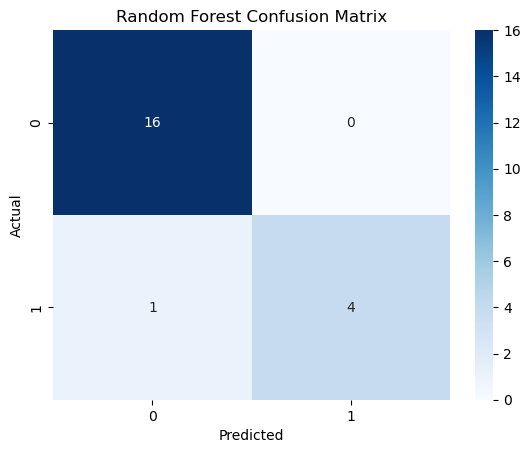

In [50]:
cm = confusion_matrix(y_test, y_pred_rf)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.show()

In [51]:
importance = pd.DataFrame({
    'Feature': x.columns,
    'Importance': rf_model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

importance

,Feature,Importance
4,competitiveness,0.571445
2,financial_flexibility,0.178872
3,credibility,0.175466
0,industrial_risk,0.030884
5,operating_risk,0.029260
1,management_risk,0.014074


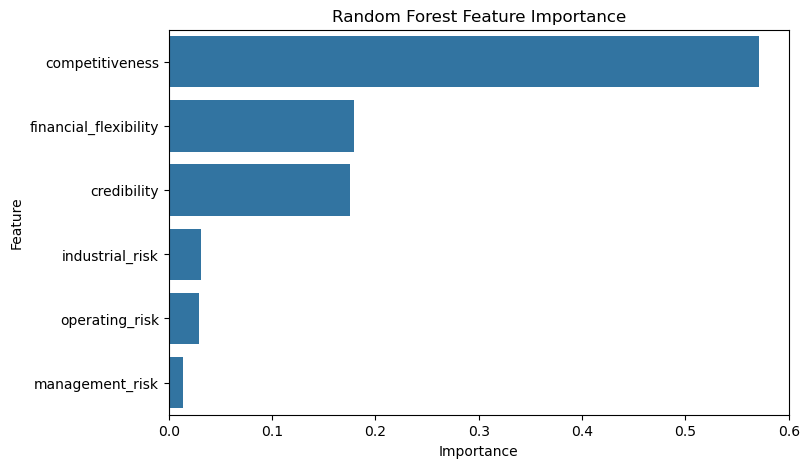

In [52]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature'
)

plt.title("Random Forest Feature Importance")

plt.show()

In [53]:
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'KNN',
        'Decision Tree',
        'Random Forest'
    ],

    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf)
    ],

    'Precision': [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_knn),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf)
    ],

    'Recall': [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_knn),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf)
    ],

    'F1 Score': [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_knn),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf)
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.952381,1.0,0.8,0.888889
1,KNN,0.952381,1.0,0.8,0.888889
2,Decision Tree,0.952381,1.0,0.8,0.888889
3,Random Forest,0.952381,1.0,0.8,0.888889


In [54]:
#Logistic Regression CV
#5-fold Stratified Cross Validation
cv = StratifiedKFold(               
    n_splits=5,
    shuffle=True,
    random_state=42
)
scores_lr = cross_val_score(
    logistic_model,
    x,
    y,
    cv=cv,
    scoring='accuracy'
)

print(scores_lr)
print("Mean:", scores_lr.mean())

[1.         0.95238095 1.         0.95       1.        ]
Mean: 0.9804761904761905


In [55]:
##Knn cv
scores_knn = cross_val_score(
    knn_model,
    x,
    y,
    cv=cv,
    scoring='accuracy'
)

print(scores_knn)
print("Mean:", scores_knn.mean())

[1.         0.95238095 1.         1.         1.        ]
Mean: 0.9904761904761905


In [56]:
#Decision Tree CV
scores_dt = cross_val_score(
    dt_model,
    x,
    y,
    cv=cv,
    scoring='accuracy'
)

print(scores_dt)
print("Mean:", scores_dt.mean())

[1.   1.   1.   0.95 0.95]
Mean: 0.9800000000000001


In [57]:
#Random Forest CV
scores_rf = cross_val_score(
    rf_model,
    x,
    y,
    cv=cv,
    scoring='accuracy'
)

print(scores_rf)
print("Mean:", scores_rf.mean())

[1.   1.   1.   0.95 1.  ]
Mean: 0.99


## Cross-Validation Comparison

In [58]:
cv_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'KNN',
        'Decision Tree',
        'Random Forest'
    ],

    'CV Accuracy': [
        scores_lr.mean(),
        scores_knn.mean(),
        scores_dt.mean(),
        scores_rf.mean()
    ]
})
cv_results= cv_results.sort_values(by='CV Accuracy', ascending=False)
print(cv_results)

                 Model  CV Accuracy
1                  KNN     0.990476
3        Random Forest     0.990000
0  Logistic Regression     0.980476
2        Decision Tree     0.980000


## Save the Best Model

In [59]:
import joblib

joblib.dump(
    rf_model,
    'bankruptcy_model.pkl'
)

['bankruptcy_model.pkl']